# Notebook 1 · Do IFC arquitetônico aos resultados em RDF

**CIV2155 · FNDE Proinfância Tipo 2 · Arquitetura R03.**

Este notebook apresenta o código selecionado, o objeto analisado e os resultados obtidos. O procedimento mantém as associações da rotina consolidada e disponibiliza uma exportação voltada à apresentação do trabalho.

**Roteiro:** importar fontes → preparar geometria → associar ambientes e esquadrias → integrar ao RDF → consultar e interpretar.

Resultado observado: 38 dos 41 espaços com associação executada, três inconclusivos, 101 pares ambiente–esquadria e 66 esquadrias distintas. A conferência documental abrange 14 ambientes; seus detalhes e os ensaios estão no [arquivo técnico do Drive](https://drive.google.com/drive/u/0/folders/1kVGXvERWXieeMeURrJF07tuLaADdrJ_O).

## 1. Preparar o ambiente e importar as fontes

Em uma cópia local, o notebook usa a pasta do repositório. No Colab, baixa os arquivos necessários da versão publicada, verificando os hashes abaixo. Se uma fonte tiver mudado, a execução para em vez de usar conteúdo diferente silenciosamente. As bibliotecas são instaladas nas versões registradas quando necessário. Ambiente usado: Python 3.12.

O IFC original é somente lido. Os arquivos intermediários ficam em `.execucao/` e os resultados de apresentação em `resultados/`.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,zipfile,subprocess,importlib.util
from urllib.request import urlretrieve
sha=lambda p:hashlib.sha256(Path(p).read_bytes()).hexdigest()
RAIZ=Path(os.environ.get('CIV2155_RAIZ',Path.cwd())).resolve()
if not (RAIZ/'codigo').is_dir() and (RAIZ.parent/'codigo').is_dir():RAIZ=RAIZ.parent
if not (RAIZ/'codigo').is_dir():RAIZ=RAIZ/'CIV2155';RAIZ.mkdir(exist_ok=True)
ARQUIVOS={'codigo/01_ambientes.rq': 'a04a6d1a02ab2603653c67abe4e530b8fd6102cbd223ea9940b1ac357910b125', 'codigo/02_esquadrias.rq': 'b9912c52ddab7b68b9bb4a10db5a1008fd074e3ecf1240040204d7c0284145a1', 'codigo/apresentar.py': '6c780d20cd029b3b8161dd53d717a48e8058019fd932cfaf087bafb4e511a4ed', 'codigo/converter_ifc.py': '0dece640f0f886e0c1e3ee18ea4ec24d6c8e80ed84e3673aac6c46b24d8a6a96', 'codigo/COPYING': 'd0495053051967ebe76fb1facd287d79d1ed800da1be75cf501a556bc39a0472', 'codigo/faces_kiavarz.py': 'ab98dbdc815bc7c61812e9e9cd2484cb0ec5e3f0ca5a94776038ef8682c83e35', 'codigo/ifc2sb_faces.py': '5932ba26c9865bb8152278238ae3e3191dc20deccb0d61576cba6358077a8bd6', 'codigo/preparar_geometria.py': 'b159077aa2395b01244b7d68920f9983d9e585f5bd63ad156a632def1bfe1363', 'codigo/publicar_resultados.py': '3d3d87c432dca8861d2563875142d0f99f7b200b2257a97a41311d20453c2f39', 'codigo/README.md': '9844da1d62ff638f15bc6b76642b7ace58840fc767642ad0721cba3faf32d5a4', 'codigo/recuperar_geometria.py': 'f60a376111593ac33b5a7814f121bd49cfa77d22e712879519b30dd8a705b265', 'codigo/rotina_multiambientes.py': '7fcf7b423871303914950850ff34c425a43cc551f003f0aae0734a7391fa40fe', 'codigo/Vocabulario.ttl': '646fa32dd9766c470622d110dceff247667e3be02e737e9874cb04cfa27a4f5a', 'dados/Conversao_IFCtoLBD.zip': '5fea3fc3016c96abb93b16b07497c0b0a64284eb3e2e59020ad3bf67552caefb', 'dados/Identidades_IFC_RDF.csv': 'a067b111690334ecad718e046c3dc6fe1154dc4e30d44cd998fa6c6d71e0abb6', 'dados/Origem.json': 'ce8e93c41186a6d18ab15824b14cbb44e3bf220e0100e79761680fb275b57416', 'dados/README.md': '21ffc999fea67a15e9f39bdccc468c0365a7944081b500fcb238d5013142d542', 'dados/TIPO2-ARQ-DTV_R03.ifc.zip': '19053ddc0698742ab28b1af2b8ee573bfe96ef5fec4f148d115cc4c8d8bfc770', 'requirements.txt': 'a1b5eaf150f386a65cf3d213baa0853e61abb035b4ba25313ddc4a96553cf3ec', 'resultados/Analise_Documental_14_Ambientes.csv': 'd837238c0e89bb32f1734206cc559e89da4789b49f3593a208d128791b33b499', 'codigo/visualizar_rdf.py': 'e399ce9cccd281767b866cc48bed0c897b4eba1fa6db99da5f0786b3768451b4'}
for rel,esperado in ARQUIVOS.items():
    p=RAIZ/rel;p.parent.mkdir(parents=True,exist_ok=True)
    if not p.exists():urlretrieve('https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/'+rel,p)
    if sha(p)!=esperado:raise ValueError('Arquivo difere da fonte deste notebook: '+rel)
deps={'numpy':'numpy==2.5.4','ifcopenshell':'ifcopenshell==0.8.4','OCP':'cadquery-ocp==7.8.1.1.post1','shapely':'shapely==2.2.0','rdflib':'rdflib==7.1.4','matplotlib':'matplotlib==3.10.7'}
from importlib.metadata import version
nomes={'OCP':'cadquery-ocp'}
instalar=[spec for mod,spec in deps.items() if importlib.util.find_spec(mod) is None or version(nomes.get(mod,mod))!=spec.split('==')[1]]
if instalar:subprocess.check_call([sys.executable,'-m','pip','install',*instalar])
sys.path.insert(0,str(RAIZ/'codigo'))
TRABALHO=RAIZ/'.execucao';TRABALHO.mkdir(exist_ok=True)
SAIDA=RAIZ/'resultados';SAIDA.mkdir(exist_ok=True)
with zipfile.ZipFile(RAIZ/'dados/TIPO2-ARQ-DTV_R03.ifc.zip') as z:
    IFC=TRABALHO/'TIPO2-ARQ-DTV_R03.ifc';IFC.write_bytes(z.read(IFC.name))
assert sha(IFC)=='0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a'
print('Entradas e código importados. IFC preservado; pasta de trabalho:',TRABALHO)

Entradas e código importados. IFC preservado; pasta de trabalho: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\bim-ontology-CIV2155\.execucao


## 2. Usar a conversão semântica executada

[Bonduel et al. (2018)](https://ceur-ws.org/Vol-2159/04paper.pdf) fundamentam a transformação para Linked Building Data. O motor efetivamente executado foi **IFCtoLBD 2.49.0**, com duas correções textuais para preservar Unicode e apóstrofos. São 56.961 triplas na base, sem os antigos complementos geométricos.

O padrão abaixo reutiliza explicitamente esse resultado. Para refazer a conversão, defina `RECONVERTER=True`: o módulo baixa a distribuição oficial e fontes fixadas por hash, aplica as duas alterações, compila-as e executa o motor. Requer Java 21 JDK; no Windows, informe `CIV2155_JAVA` com o caminho de `java.exe`. No Colab, o módulo instala o JDK se necessário. As URIs mantêm o namespace original para preservar identidades.

In [2]:
from rdflib import Graph
RECONVERTER=False
BASE_RDF=TRABALHO/'arquitetura_ifctolbd.ttl'
if RECONVERTER:
    from converter_ifc import converter
    converter(IFC,BASE_RDF,TRABALHO)
else:
    with zipfile.ZipFile(RAIZ/'dados/Conversao_IFCtoLBD.zip') as z:BASE_RDF.write_bytes(z.read(BASE_RDF.name))
    assert sha(BASE_RDF)=='ac9480c1a7d01c7ee1e54891d778795a0c9b15f06f092df5e22159018d88db15'
base=Graph().parse(BASE_RDF,format='turtle')
print('Conversão semântica:',len(base),'triplas; reutilizada:',not RECONVERTER)
del base

Conversão semântica: 56961 triplas; reutilizada: True


## 3. Preparar espaços, paredes e aberturas

A adaptação parcial do [IFC2SB, Fichter et al. (2021)](https://doi.org/10.26868/25222708.2021.30156) mantém faces parentais e recortes de aberturas. Não executa o algoritmo completo dos autores. Cada parede é preparada uma vez e compartilhada entre os espaços.

O espaço precisa formar sólido fechado e válido, sem arestas livres ou múltiplas, com volume positivo. Nos casos que falham no caminho estrito, tenta-se ShapeFix e costura em cópia, com tolerâncias de 1, 10 e 100 µm. Exigem-se mesmo número de faces, variação relativa de área ≤10⁻⁶ e desvio de vértices/caixa ≤0,1 mm. Não se cria uma caixa ou tampão para aprovar a geometria.

A distinção entre diagnóstico, correção e pré-condições segue a orientação de [Lilis et al. (2026)](https://doi.org/10.1016/j.jobe.2026.115667); a implementação conservadora com OCP é própria. O preparo é refeito a partir do IFC nesta célula. Uma geometria inconclusiva continua visível nos resultados.

In [3]:
from preparar_geometria import preparar
CACHE=TRABALHO/'geometria'
catalogo=preparar(IFC,CACHE,workers=2)
print(catalogo['resumo'])
print('Espaços inconclusivos:',[r['nome'] for r in catalogo['espacos'] if not r['estado'].startswith('volume_')])

ESPAÇO 1 INFANTIL 1 inconclusivo_preparacao_espaco


ESPAÇO 2 INFANTIL 2/3 volume_fechado_aceito


ESPAÇO 3 INFANTIL 4 volume_fechado_aceito


ESPAÇO 4 INFANTIL 5 inconclusivo_preparacao_espaco


ESPAÇO 5 SANIT. INFANTIL FEM. volume_fechado_aceito


...

PAREDES PREPARADAS 400 / 457


PAREDES PREPARADAS 425 / 457


PAREDES PREPARADAS 450 / 457


PREPARO CONCLUÍDO {"espacos": 41, "espacos_com_volume_aceito": 38, "paredes": 457, "paredes_preparadas": 457, "paredes_inconclusivas": 0, "aberturas_ifc": 184, "produtos_examinados": 188}


{'espacos': 41, 'espacos_com_volume_aceito': 38, 'paredes': 457, 'paredes_preparadas': 457, 'paredes_inconclusivas': 0, 'aberturas_ifc': 184, 'produtos_examinados': 188}
Espaços inconclusivos: ['INFANTIL 1', 'INFANTIL 5', 'AMAMENTAÇÃO']


## 4. Associar esquadrias aos ambientes

A rotina adapta orientação, projeção/interseção, raios e sondas de [Kiavarz et al. (2023)](https://doi.org/10.3390/buildings13020350), §§4.2.2–4.4. O IFC não atende ao `BoundedBy` exigido pelo fluxo literal do artigo. A extensão usa faces do espaço e da parede e conserva a cadeia **espaço → interface → parede → abertura → preenchimento**.

O pré-filtro por caixa apenas reduz candidatos. A associação exige interseção local, normais opostas, distância entre planos ≤0,1 mm e qualificação com raios/sondas de 1 mm no sólido do espaço. A normalização de desvios numéricos até 0,1 mm preserva anéis e não aumenta a tolerância de contato. A separação entre representações segue a inspiração de [Ying e Lee (2021)](https://doi.org/10.1016/j.autcon.2021.103659); a normalização é uma adaptação própria.

O código aplica os mesmos parâmetros aos 41 espaços. As pranchas e a tabela documental não são entradas da predição. As 101 associações não representam 101 peças distintas nem confirmação arquitetônica de todos os casos.

In [4]:
from rotina_multiambientes import executar_lote
BRUTOS=TRABALHO/'associacoes'
lote=executar_lote(IFC,CACHE,BRUTOS)
print('Pares:',lote['pares_ambiente_esquadria'],'; esquadrias distintas:',lote['esquadrias_distintas_associadas'])

AMBIENTE 1 / 41 INFANTIL 1 inconclusivo_preparacao_espaco {'interfaces': None, 'esquadrias': None, 'internos': None, 'componentes': None}


AMBIENTE 2 / 41 INFANTIL 2/3 associacao_executada_com_pendencias {'interfaces': 210, 'interfaces_qualificadas': 210, 'paredes_com_interface': 18, 'esquadrias': 3, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 21}


AMBIENTE 3 / 41 INFANTIL 4 associacao_executada_com_pendencias {'interfaces': 163, 'interfaces_qualificadas': 163, 'paredes_com_interface': 16, 'esquadrias': 3, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 21}


AMBIENTE 4 / 41 INFANTIL 5 inconclusivo_preparacao_espaco {'interfaces': None, 'esquadrias': None, 'internos': None, 'componentes': None}


AMBIENTE 5 / 41 SANIT. INFANTIL FEM. associacao_executada_com_pendencias {'interfaces': 373, 'interfaces_qualificadas': 373, 'paredes_com_interface': 25, 'esquadrias': 2, 'outros_preenchimentos': 0, 'internos': 2, 'componentes': 0, 'problemas': 21}


...

AMBIENTE 39 / 41 LIXO associacao_executada {'interfaces': 3, 'interfaces_qualificadas': 3, 'paredes_com_interface': 3, 'esquadrias': 2, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 0}


AMBIENTE 40 / 41 FRALDÁRIO associacao_executada {'interfaces': 67, 'interfaces_qualificadas': 67, 'paredes_com_interface': 9, 'esquadrias': 2, 'outros_preenchimentos': 0, 'internos': 2, 'componentes': 0, 'problemas': 0}


AMBIENTE 41 / 41 CIRCULAÇÃO associacao_executada {'interfaces': 36, 'interfaces_qualificadas': 36, 'paredes_com_interface': 3, 'esquadrias': 1, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 0}


{
  "ifc_sha256": "0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a",
  "parametros_comuns": {
    "desvio_max_projecao_planar_m": 0.0001,
    "distancia_planos_m": 0.0001,
    "area_min_m2": 1e-08,
    "tol_normal": 1e-10,
    "sonda_principal_m": 0.001,
    "tolerancia_classificacao_m": 1e-07,
    "tolerancia_contorno_parental_m2": 1e-07,
    "tolerancia_internos_m": 1e-05,
    "distancia_componente_m": 0.25,
    "margem_componente_m": 0.02
  },
  "estados": {
    "inconclusivo_preparacao_espaco": 3,
    "associacao_executada_com_pendencias": 6,
    "associacao_executada": 32
  },
  "espacos_solicitados": 41,
  "espacos_com_associacao_executada": 38,
  "espacos_inconclusivos": 3,
  "pares_ambiente_esquadria": 101,
  "esquadrias_distintas_associadas": 66,
  "cache_catalogo_sha256": "6e7451a74feb7fe1601e61fb510c5afe4c769fc6aabebec10233b287cc14c5fc",
  "preparo_global": {
    "espacos": 41,
    "espacos_com_volume_aceito": 38,
    "paredes": 457,
    "paredes_preparadas"

Pares: 101 ; esquadrias distintas: 66


## 5. Integrar ao grafo e consultar os resultados

O exportador preserva a base semântica como conjunto de triplas e acrescenta estados, interfaces, recortes e associações da rotina selecionada. A integração usa GlobalId/URI. O vocabulário geométrico de [BimSPARQL, Zhang et al. (2018)](https://doi.org/10.3233/SW-180297) registra os polígonos em WKT 3D por `geom:asBody`; o motor Java de funções geométricas dos autores não é executado.

O referencial é cartesiano, em metros, conforme o IFC; não é CRS84. O grafo entregue é reaberto e recebe duas consultas SPARQL. Ambientes inconclusivos não recebem uma contagem falsa de zero. Esta exportação reúne apenas a base e os resultados primários; a contagem de triplas difere dos antigos grafos de desenvolvimento.

{
  "ifc_sha256": "0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a",
  "espacos_solicitados": 41,
  "espacos_com_associacao": 38,
  "espacos_inconclusivos": 3,
  "estados": {
    "associacao_executada": 32,
    "associacao_executada_com_pendencias": 6,
    "inconclusivo_preparacao_espaco": 3
  },
  "pares_ambiente_esquadria": 101,
  "esquadrias_distintas": 66,
  "interfaces_candidatas": 3011,
  "recortes_aberturas": 222,
  "triplas_base_semantica": 56961,
  "triplas_grafo_entregue": 80234,
  "coordenadas": "Referencial cartesiano do IFC; metros; não CRS84.",
  "alcance": "Associação geométrica no mesmo IFC; conferência documental em 14 ambientes. Não certifica completude arquitetônica."
}


Ambientes consultados no grafo:


ambiente,nome,estado,quantidade
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_29b9da17-2ef2-4b72-a017-18746cd56f9c,ADMINISTRAÇÃO,associacao_executada,2
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_5e17dff5-4488-4291-abba-92395059a4d4,AMAMENTAÇÃO,inconclusivo_preparacao_espaco,indisponível
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_866f4039-c7ae-4716-8b37-0fa8600f322b,BERÇARIO,associacao_executada,3
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_d547a7f0-291f-42b1-a92e-3fd73666b6c9,CASA DE BOMBAS,associacao_executada,0
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_d762493a-e4ae-4433-9c62-813f2b077a13,CASTELO D'ÁGUA,associacao_executada,0
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_095139dc-3826-415a-aa40-867ca7c7929f,CIRCULAÇÃO,associacao_executada,2
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_265787d1-8228-414d-9925-d859c736ec35,CIRCULAÇÃO,associacao_executada,6
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_4a1d4377-4c41-4821-a1f5-32bdd761c397,CIRCULAÇÃO,associacao_executada,1
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_f6222343-99a3-43d8-9f56-0ec91c2f8c48,CIRCULAÇÃO,associacao_executada,11
https://github.com/prcgui/bim-ontology-CIV2155/id/notebook1-v03/space_03fbb3d2-8cec-4d81-a3b6-f4109724b3d5,COPA FUNCIONÁRIOS,associacao_executada,6


Pares ambiente–esquadria consultados: 101


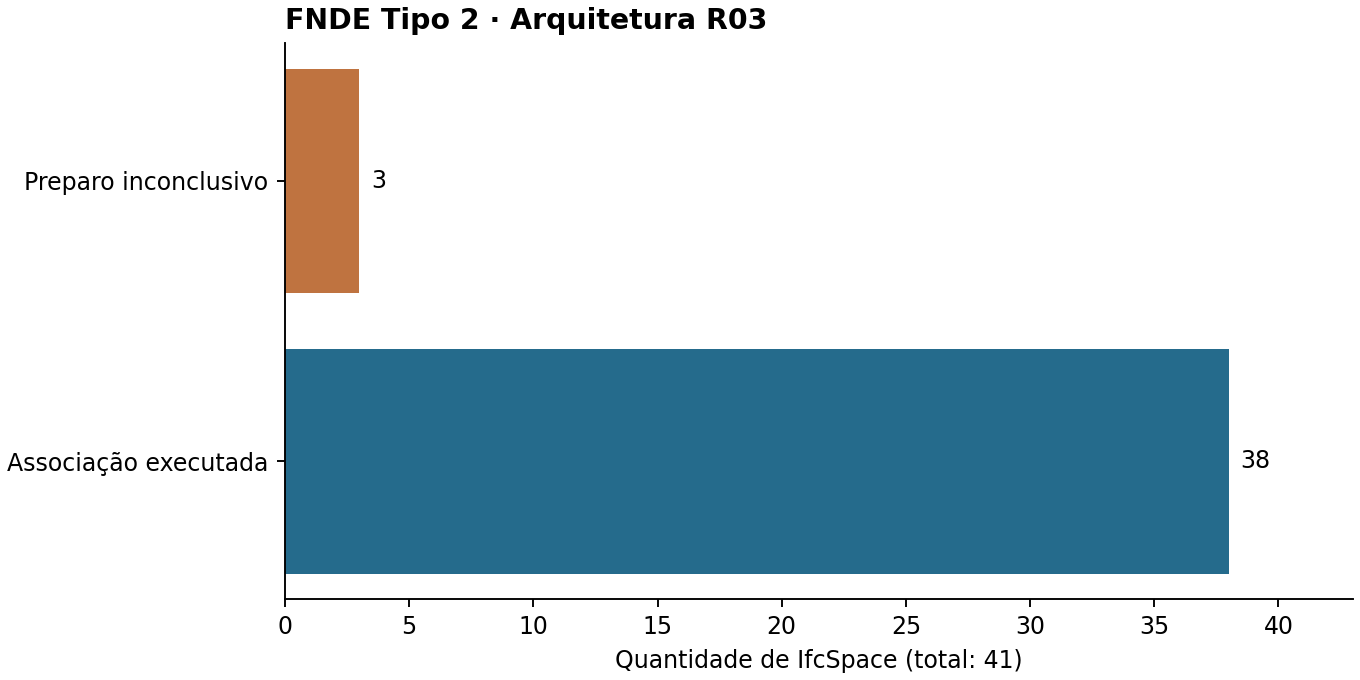

In [5]:
from publicar_resultados import publicar
from apresentar import figura
resumo=publicar(BRUTOS,BASE_RDF,RAIZ/'dados/Identidades_IFC_RDF.csv',SAIDA)
figura(SAIDA)
print(json.dumps(resumo,ensure_ascii=False,indent=2))
with zipfile.ZipFile(SAIDA/'Arquitetura_Analisada.zip') as z:
    grafo=Graph().parse(data=z.read('Arquitetura_Analisada.ttl'),format='turtle')
from IPython.display import display,Image,HTML
from html import escape
def tabela(resultado):
    cabecalho="".join("<th>"+escape(str(v))+"</th>" for v in resultado.vars)
    linhas="".join("<tr>"+"".join("<td>"+escape(str(v) if v is not None else "indisponível")+"</td>" for v in row)+"</tr>" for row in resultado)
    return HTML("<table><thead><tr>"+cabecalho+"</tr></thead><tbody>"+linhas+"</tbody></table>")
print('Ambientes consultados no grafo:')
display(tabela(grafo.query((RAIZ/'codigo/01_ambientes.rq').read_text(encoding='utf8'))))
print('Pares ambiente–esquadria consultados:',len(list(grafo.query((RAIZ/'codigo/02_esquadrias.rq').read_text(encoding='utf8')))))
display(Image(filename=str(SAIDA/'Cobertura.png')))

## 6. Ver o RDF em caixas, como na apresentação

As figuras abaixo são geradas diretamente do grafo entregue nesta execução. Recursos aparecem em caixas coloridas, valores em cinza e predicados nas setas. A primeira mostra a identidade da cozinha; a segunda mostra um caminho real da associação com a porta PA2. O código também grava a [organização espacial dos 41 ambientes](../resultados/grafo_rdf/Organizacao_Espacial.png).

Os recortes Turtle preservam as URIs e os valores originais. O arranjo gráfico serve à leitura das relações; suas posições não representam localização física. Na figura de identidade, “nome”, “nome descritivo”, “categoria” e “GlobalId” são legendas simplificadas de predicados, discriminados no [README das figuras](../resultados/grafo_rdf/README.md). A relação geométrica com PA2 é um exemplo de uma das nove esquadrias associadas à cozinha, sem ampliar a confirmação documental dos casos.

A [aplicação publicada no GitHub Pages](https://prcgui.github.io/bim-ontology-CIV2155/) permite explorar a fotografia do resultado disponibilizado no repositório; as figuras desta célula são refeitas para o grafo da execução. Base técnica da geração: [RDFLib](https://rdflib.readthedocs.io/en/latest/intro_to_graphs/) e [Matplotlib](https://matplotlib.org/3.10.7/users/explain/text/annotations.html).

Figuras RDF geradas a partir de 80234 triplas: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\bim-ontology-CIV2155\resultados\grafo_rdf


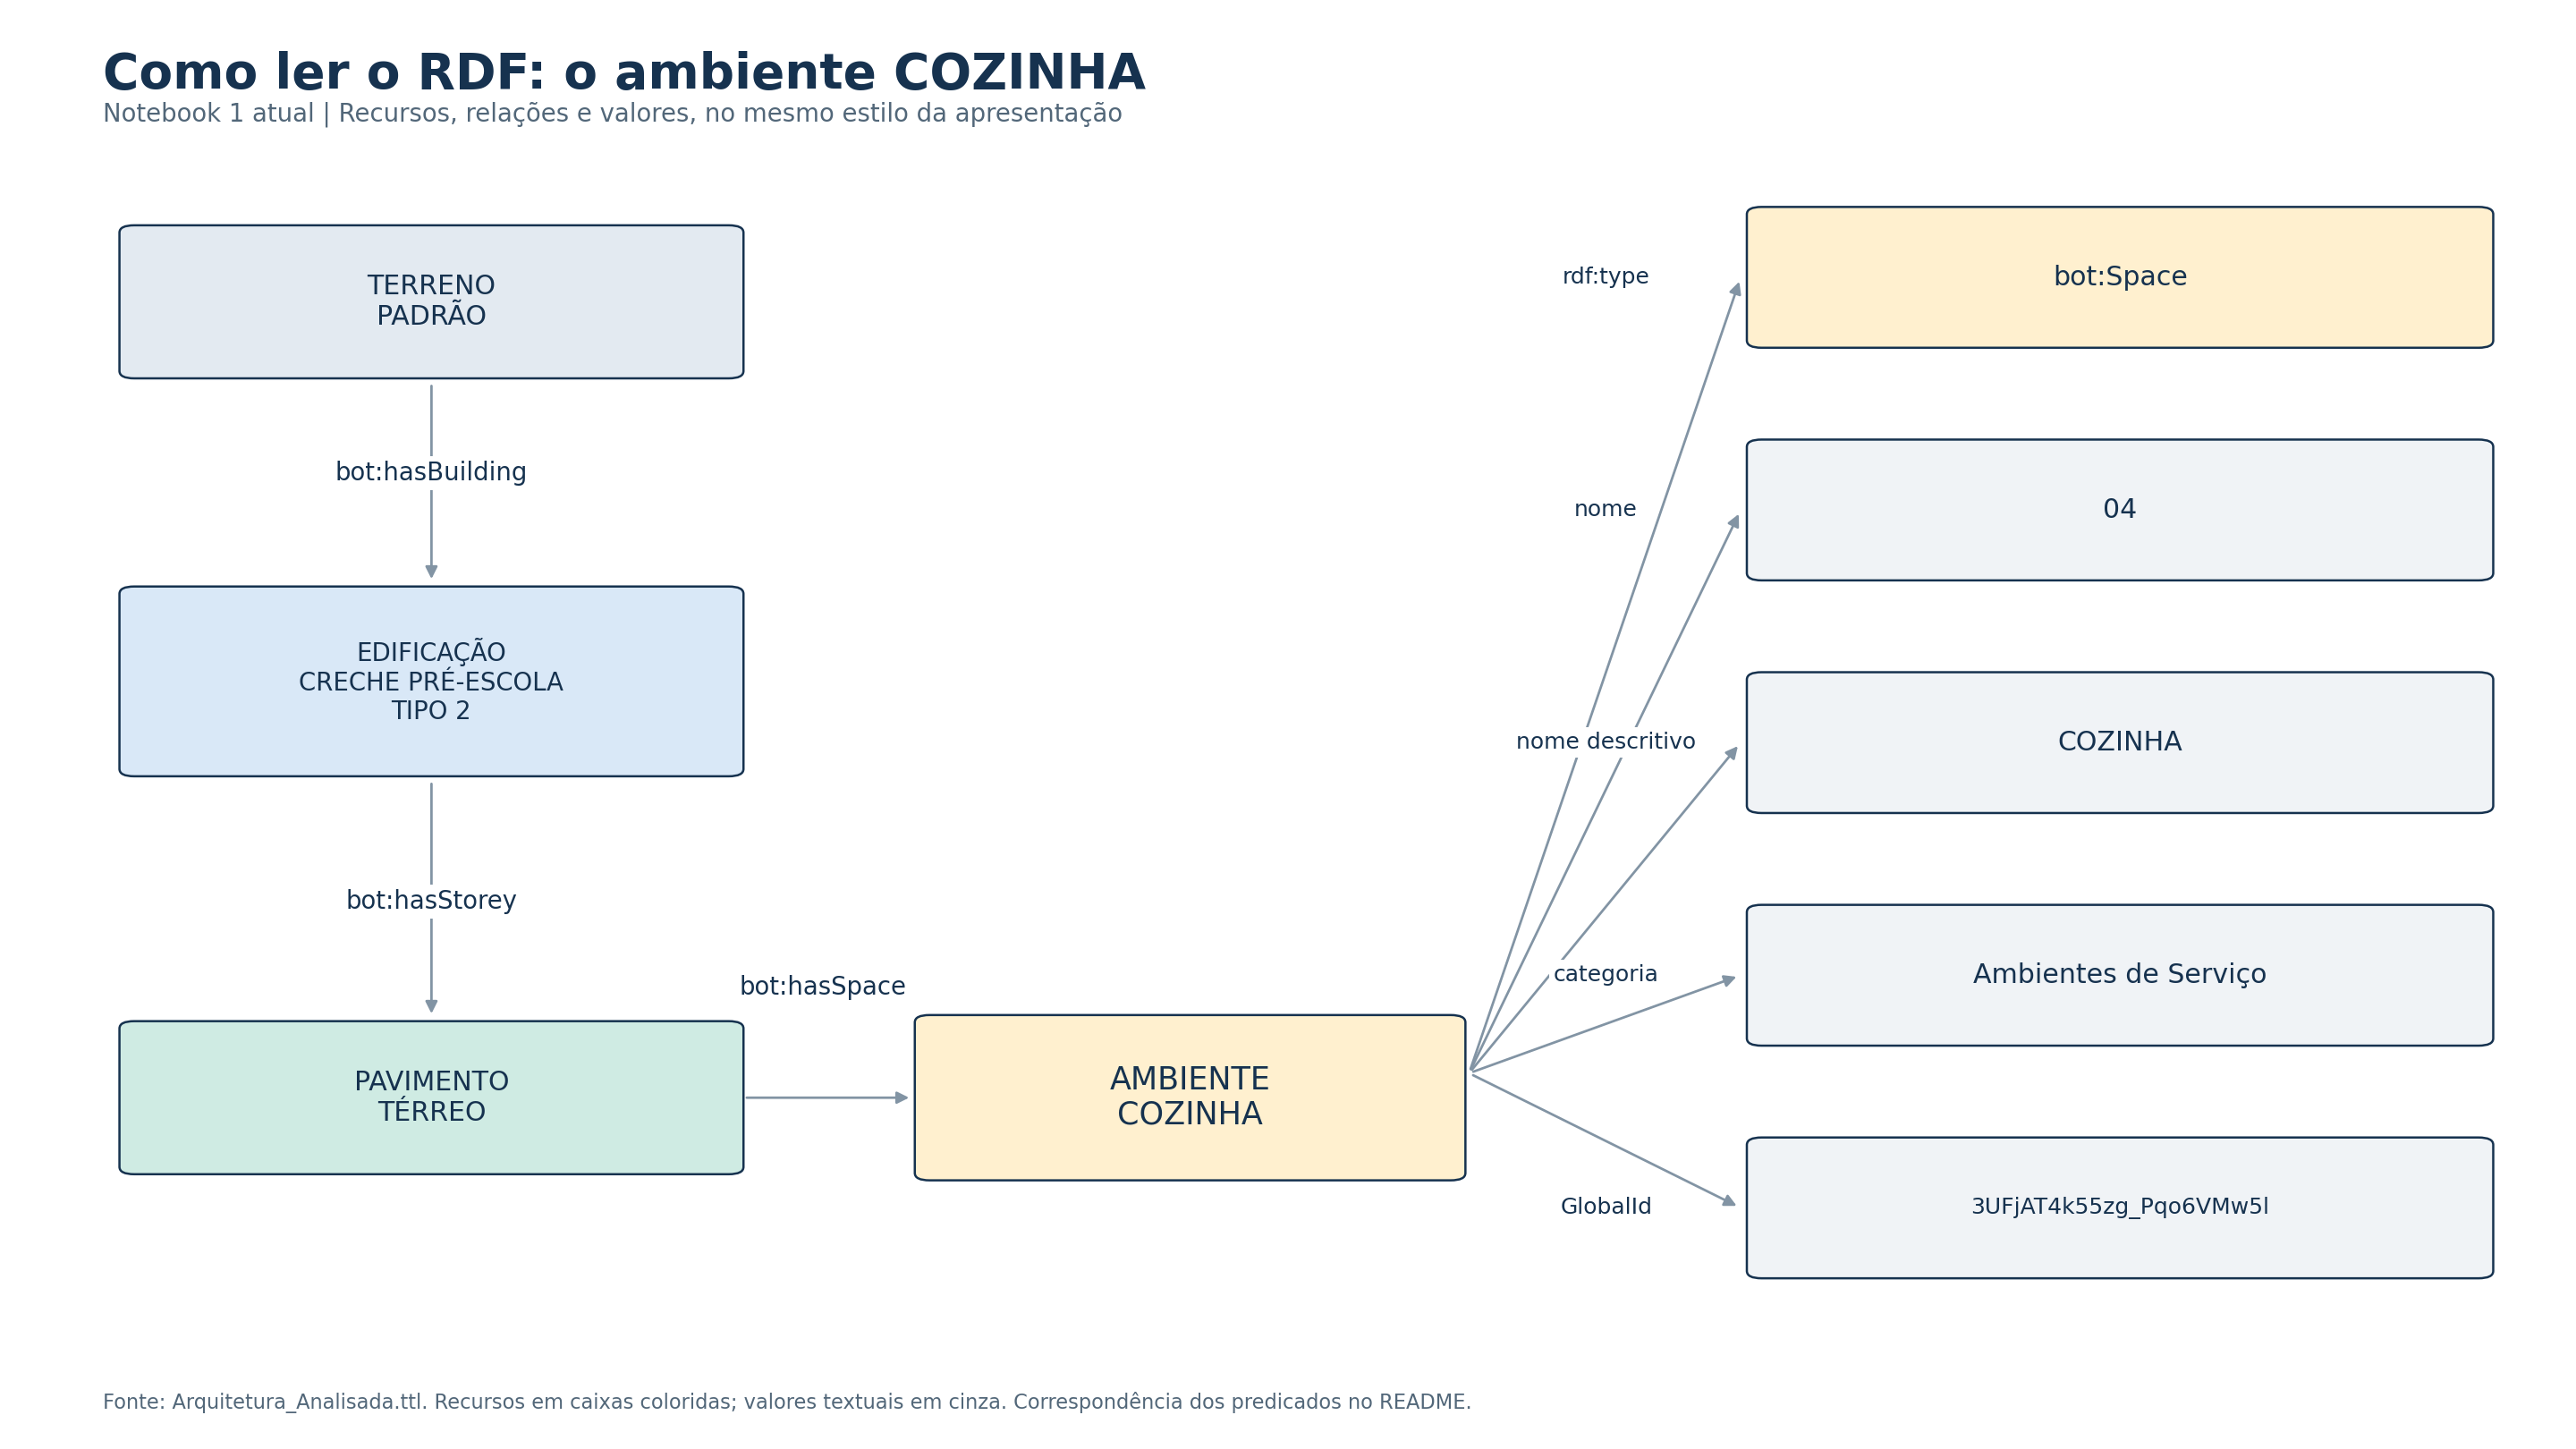

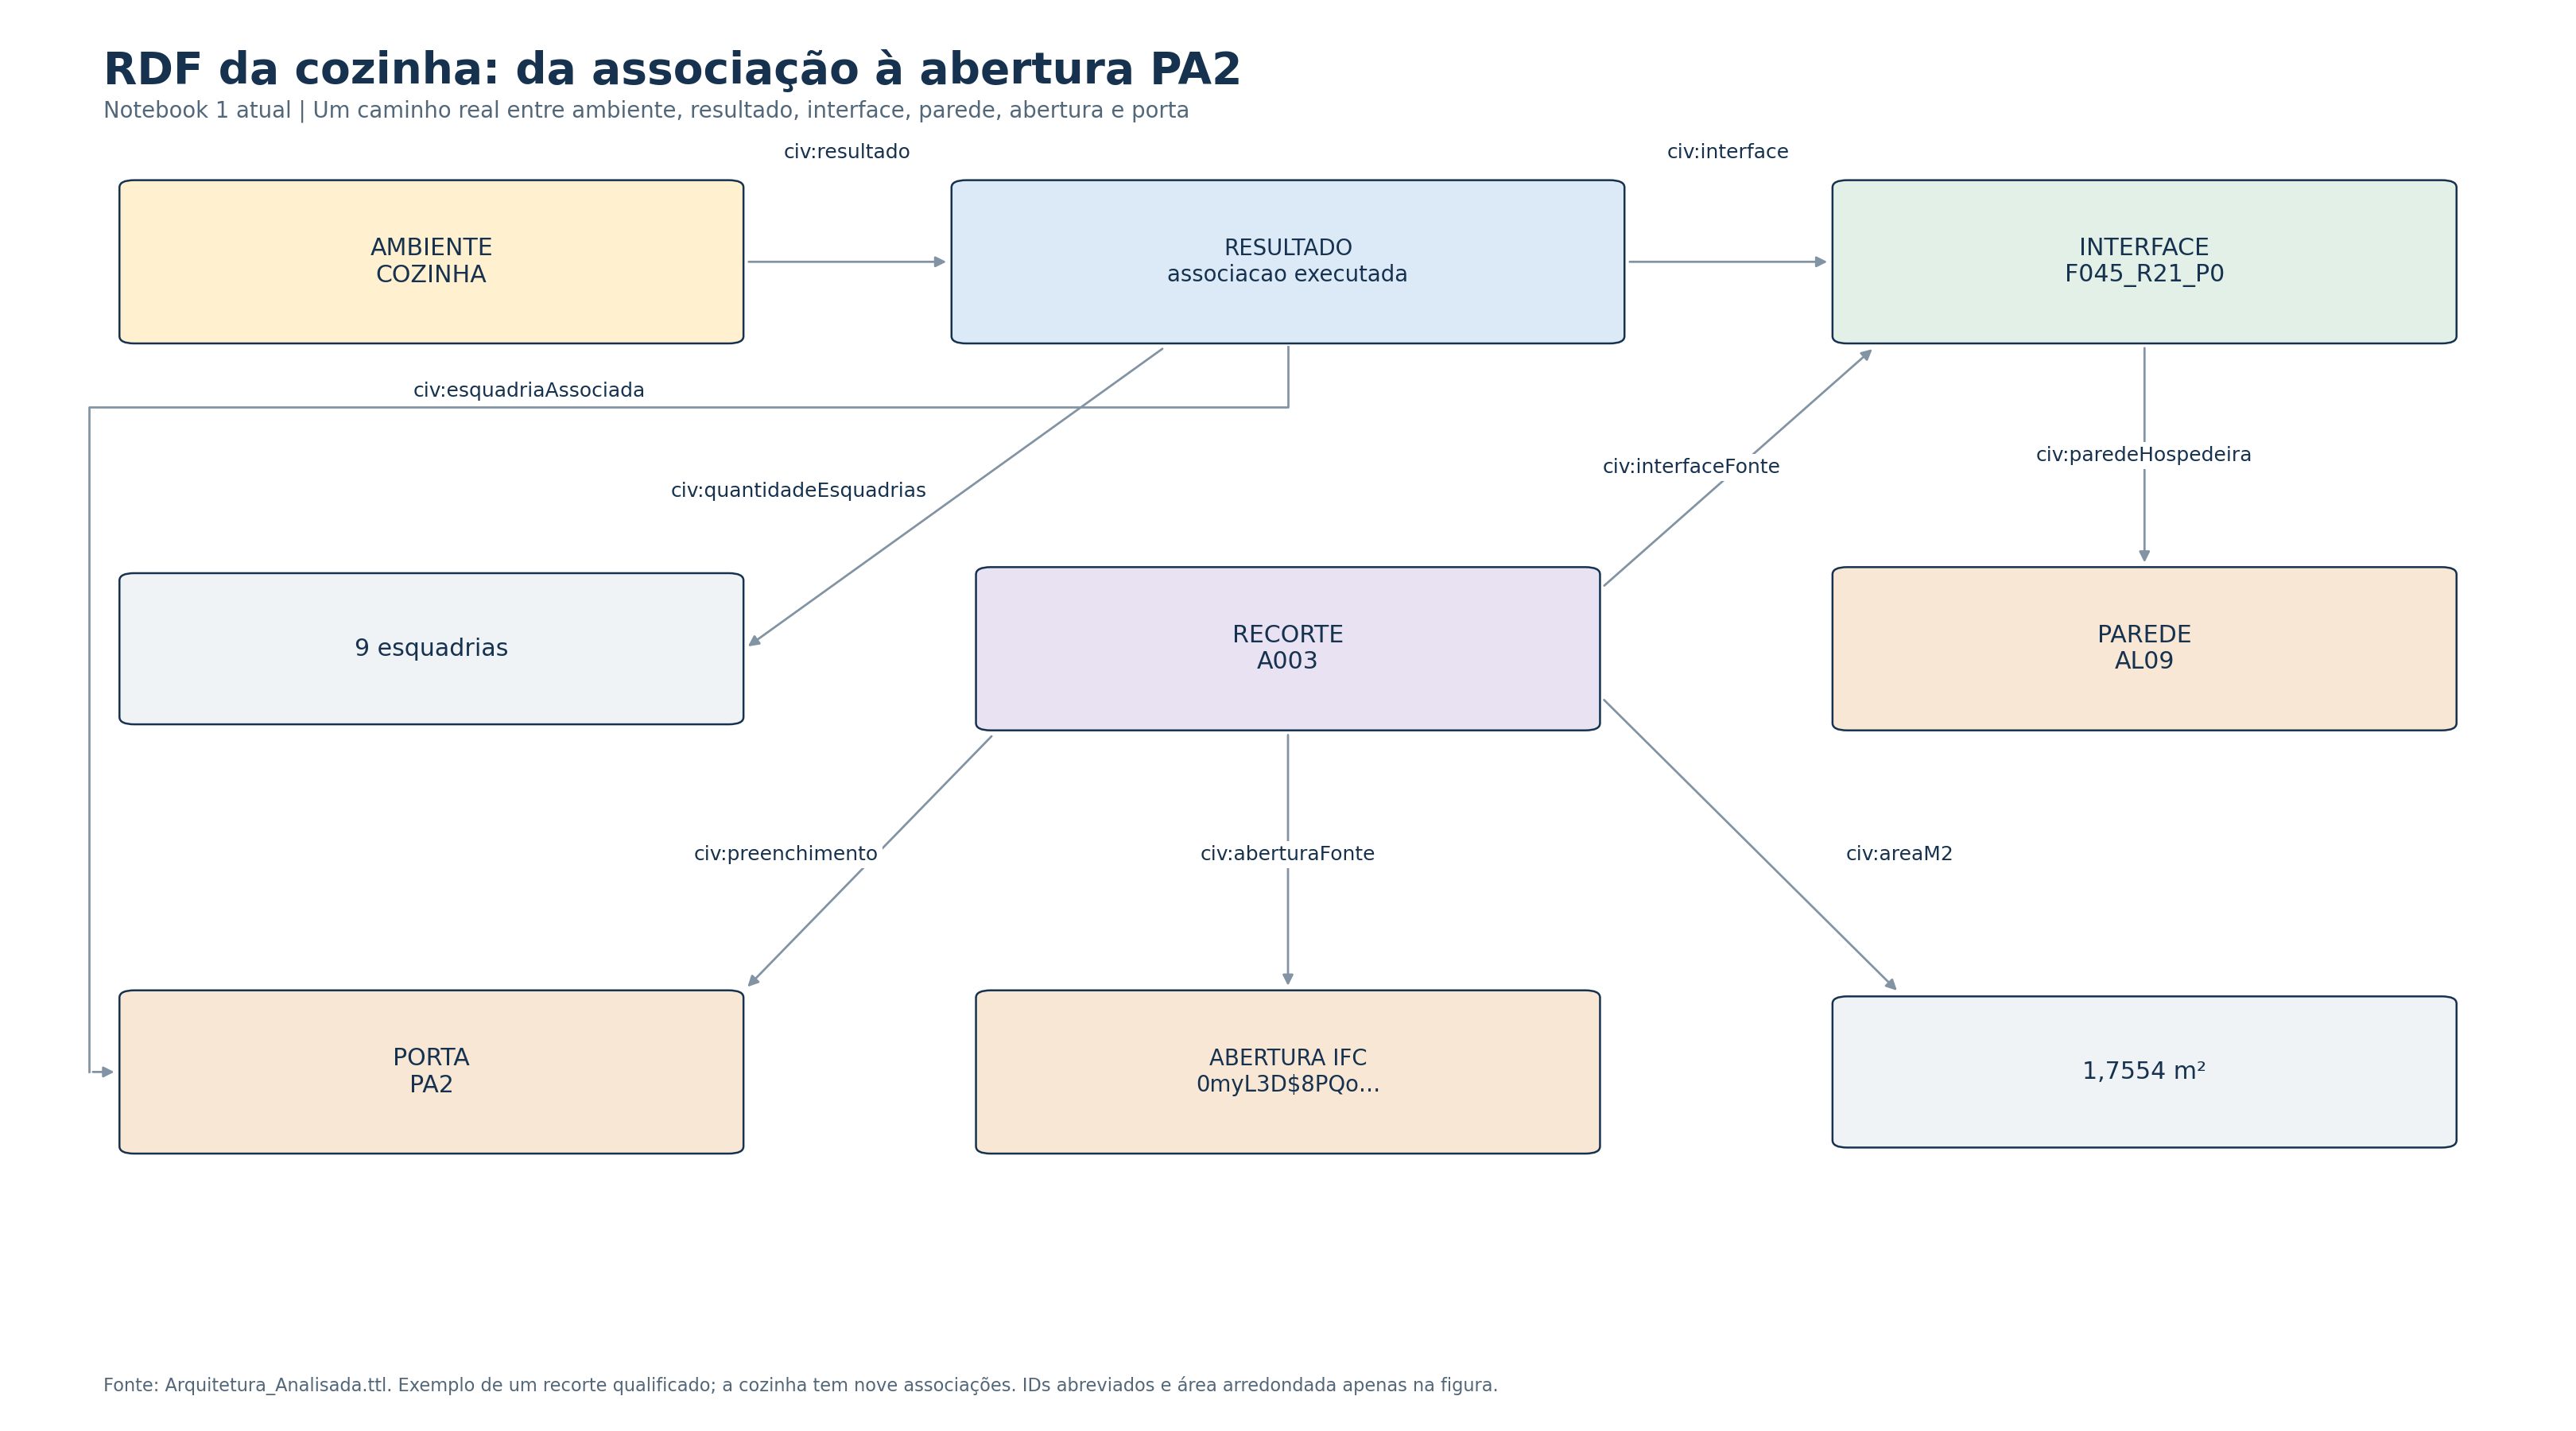

Organização espacial, PNG/SVG e recortes Turtle: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\bim-ontology-CIV2155\resultados\grafo_rdf


In [6]:
from visualizar_rdf import gerar_figuras
from IPython.display import display,Image
figuras_rdf=gerar_figuras(SAIDA/'Arquitetura_Analisada.zip',SAIDA/'grafo_rdf')
display(Image(filename=str(SAIDA/'grafo_rdf/Cozinha_Identidade.png'),width=1100))
display(Image(filename=str(SAIDA/'grafo_rdf/Cozinha_Associacao_PA2.png'),width=1100))
print('Organização espacial, PNG/SVG e recortes Turtle:',SAIDA/'grafo_rdf')

## 7. Interpretar o que foi analisado nas pranchas

A análise documental já realizada usa as **pranchas oficiais R03 02, 20 e 24–27** em 14 ambientes. A célula apresenta seu quadro agregado; não refaz a leitura arquitetônica nem os ensaios de desenvolvimento. As pranchas estão em `dados/pranchas/` no GitHub, e a evidência caso a caso está no [Drive](https://drive.google.com/drive/u/0/folders/1kVGXvERWXieeMeURrJF07tuLaADdrJ_O).

Foram selecionados 43 positivos, 39 negativos e um caso indeterminado. Em ambientes processados: **39 positivos recuperados, zero falsos positivos, uma omissão e 37 negativos excluídos**. Na falha de preparo de Infantil 1, há outros três positivos sem resultado e dois negativos não avaliáveis. A recuperação global é 39/43 = **90,7%**, incluindo os três positivos sem resultado no denominador.

**Cozinha:** nove esquadrias associadas, das quais oito positivas na referência e JA-09 indeterminada; seis negativos selecionados não associados. **Administração:** JA-04 permanece omissão, com afastamento investigado de aproximadamente 10 mm, acima da tolerância primária. **Infantil 1, Infantil 5 e Amamentação:** preparo inconclusivo; ausência de resultado não significa ausência de esquadrias.

TP/FP/FN/TN na tabela referem-se somente aos casos avaliáveis após execução. Os campos de indisponibilidade por preparo são separados. A amostra foi construída com leitura assistida por IA e consultada durante o desenvolvimento, sem avaliação cega ou externa. A rotina não certifica todas as 101 associações, o fechamento global, a contenção de elementos ou outro edifício.

In [7]:
import csv
with (SAIDA/'Analise_Documental_14_Ambientes.csv').open(encoding='utf-8-sig') as fp:
    analise=list(csv.DictReader(fp))
for r in analise:
    print(r['nome'],': TP=',r['TP'],'FP=',r['FP'],'FN=',r['FN'],'TN=',r['TN'],
          '; positivos sem resultado=',r['positivos_nao_recuperados_por_preparacao'])
print('Recuperação na amostra: 39/43 =',round(100*39/43,1),'%')
print('IFC original preservado:',sha(IFC)=='0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a')

COZINHA : TP= 8 FP= 0 FN= 0 TN= 6 ; positivos sem resultado= 0
DESPENSA : TP= 3 FP= 0 FN= 0 TN= 2 ; positivos sem resultado= 0
COPA FUNCIONÁRIOS : TP= 6 FP= 0 FN= 0 TN= 3 ; positivos sem resultado= 0
VEST. FUNC. FEM. : TP= 2 FP= 0 FN= 0 TN= 3 ; positivos sem resultado= 0
VEST. FUNC. MASC. : TP= 2 FP= 0 FN= 0 TN= 3 ; positivos sem resultado= 0
SANIT. PCD FEM. : TP= 2 FP= 0 FN= 0 TN= 3 ; positivos sem resultado= 0
SANIT. PCD MASC. : TP= 2 FP= 0 FN= 0 TN= 3 ; positivos sem resultado= 0
SALA DE ATENDIMENTO : TP= 2 FP= 0 FN= 0 TN= 2 ; positivos sem resultado= 0
SALA PROF. / REUNIÕES : TP= 2 FP= 0 FN= 0 TN= 2 ; positivos sem resultado= 0
LACTÁRIO : TP= 3 FP= 0 FN= 0 TN= 3 ; positivos sem resultado= 0
INFANTIL 2/3 : TP= 3 FP= 0 FN= 0 TN= 3 ; positivos sem resultado= 0
ADMINISTRAÇÃO : TP= 2 FP= 0 FN= 1 TN= 2 ; positivos sem resultado= 0
INFANTIL 1 : TP= 0 FP= 0 FN= 0 TN= 0 ; positivos sem resultado= 3
LAVANDERIA / ROUPARIA : TP= 2 FP= 0 FN= 0 TN= 2 ; positivos sem resultado= 0
Recuperação na a

## Conclusão

O preparo controlado e as interfaces locais permitiram executar a associação além da cozinha: **38 espaços com resultado e três inconclusivos**. A solução selecionada produz **101 pares, 66 esquadrias distintas**, e recupera **39/43 positivos** na amostra documental de desenvolvimento. A ampliação observada em relação ao procedimento anterior foi de 29 para 38 espaços e de 35 para 39 positivos na mesma amostra.

O grafo permite consultar o que o código associou e conserva os estados de inconclusão. Os limites documentais e geométricos permanecem explícitos. A [bibliografia aplicada](https://github.com/prcgui/bim-ontology-CIV2155/blob/main/referencias/README.md) discrimina cada contribuição; auditorias, alternativas e comparações permanecem no Drive.